# 02 environmentを用いた2-site DMRG sweep

このNotebookでは、Notebook 00の2-site局所更新とNotebook 01のMPO・Hamiltonian environmentを接続し、開境界の横磁場Ising鎖に対する**右向きpassと左向きpassの1往復**を実装します。

到達点は、次の処理を自分でつなげ、各段階を独立に検証できることです。

```text
2サイトをまとめる
        ↓
environmentから2-site有効Hamiltonianを作る
        ↓
局所最小固有ベクトルを求める
        ↓
SVDで分割・切り捨て・再正規化する
        ↓
environmentを更新して中心を移動する
        ↓
右向きpassと左向きpassを1回ずつ行う
```

ここでは、一方向の移動を`pass`、右向きと左向きを合わせた1往復を`sweep`と呼びます。複数sweepによる収束、Lanczos法、ニューラルネットワークへの応用には進みません。


## 1. 学習の進め方

- `___`が実装する箇所です。
- 各TODOの前に、何を計算し、どの条件を満たすかを書いてあります。
- TODOの答えになる`einsum`文字列や完成コードは、このNotebook内の別セルにも掲載しません。
- TODOが未回答なら、その段階と依存する後続段階を`TODO`または`SKIP`にします。
- 数値が計算できた場合はassertを実行し、誤った結果をSKIPとして扱いません。
- 関数は特定のサイト数やbond dimensionをグローバル変数から読まず、引数から必要な情報を取得します。

検証では、小さい系をdense化します。これは教材用の参照計算であり、大規模DMRGの実装方針ではありません。


In [32]:
from __future__ import annotations

from dataclasses import dataclass
import itertools
import math
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import sys
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import torch


def add_project_src_to_path(start: Path) -> Path:
    """プロジェクトのsrcをimport対象へ追加し、ルートを返す。"""
    for candidate in (start, *start.parents):
        src_dir = candidate / "src"
        if (src_dir / "nn_compression").is_dir():
            if str(src_dir) not in sys.path:
                sys.path.insert(0, str(src_dir))
            return candidate
    raise FileNotFoundError("src/nn_compressionを含むプロジェクトルートが見つかりません。")


PROJECT_ROOT = add_project_src_to_path(Path.cwd())

from nn_compression.compression import (  # noqa: E402
    tt_canonicality_errors,
    tt_canonicalize,
    tt_fro_norm,
    tt_reconstruct,
    tt_ranks,
)

DEVICE = torch.device("cpu")
DTYPE = torch.float64
ATOL = 1e-10
RTOL = 1e-10
SEED = 20261025

LENGTH = 6
J_COUPLING = 1.0
TRANSVERSE_FIELD = 1.2
INITIAL_BOND_DIMENSION = 2
MAX_BOND = 2
DIAGNOSTIC_PAIR_START = 2

# 各TODOでは右辺の___を実装へ置き換える。
___ = None

print("project root:", PROJECT_ROOT)
print("device / dtype:", DEVICE, DTYPE)


project root: d:\dev\nn-compression-svd-dmrg
device / dtype: cpu torch.float64


## 2. 模型と、01から再利用する完成済み部品

扱う模型はNotebook 01と同じ開境界の横磁場Ising鎖です。

$$
H
=
-J\sum_{i=1}^{L-1} Z_i Z_{i+1}
-g\sum_{i=1}^{L} X_i,
\qquad
J=1,
\qquad
g=1.2.
$$

$X,Z$はPauli行列であり、$S^\alpha=\sigma^\alpha/2$ではありません。

以下は02の新しい学習対象ではないため、完成済みで用意します。

- dense HamiltonianとMPOの構築。
- MPSの生成・正規化・正準化。
- left/right environmentの1-site更新と全位置の構築。
- MPSから全状態を復元する既存API。
- エネルギー、残差、正準性の診断。

これらの補助関数は入力Tensorからdtype・device・次元を取得し、特定の実験用グローバル変数へ依存しません。


In [33]:
def kron_all(operators: list[torch.Tensor]) -> torch.Tensor:
    """局所演算子をsite順にKronecker積する。"""
    if not operators:
        raise ValueError("operatorsは1個以上必要です。")
    result = operators[0]
    for operator in operators[1:]:
        result = torch.kron(result, operator)
    return result


def build_tfim_dense_hamiltonian(
    length: int,
    coupling: float,
    transverse_field: float,
    *,
    dtype: torch.dtype,
    device: torch.device,
) -> torch.Tensor:
    """開境界横磁場Ising鎖のdense Hamiltonianを構築する。"""
    if length < 2:
        raise ValueError("lengthは2以上にしてください。")

    identity = torch.eye(2, dtype=dtype, device=device)
    pauli_x = torch.tensor([[0.0, 1.0], [1.0, 0.0]], dtype=dtype, device=device)
    pauli_z = torch.tensor([[1.0, 0.0], [0.0, -1.0]], dtype=dtype, device=device)
    dimension = 2**length
    hamiltonian = torch.zeros((dimension, dimension), dtype=dtype, device=device)

    for site in range(length):
        operators = [identity] * length
        operators = operators.copy()
        operators[site] = pauli_x
        hamiltonian = hamiltonian - transverse_field * kron_all(operators)

    for site in range(length - 1):
        operators = [identity] * length
        operators = operators.copy()
        operators[site] = pauli_z
        operators[site + 1] = pauli_z
        hamiltonian = hamiltonian - coupling * kron_all(operators)

    return hamiltonian


def build_tfim_mpo(
    length: int,
    coupling: float,
    transverse_field: float,
    *,
    dtype: torch.dtype,
    device: torch.device,
) -> list[torch.Tensor]:
    """開境界横磁場Ising鎖のHamiltonian MPOを構築する。"""
    if length < 2:
        raise ValueError("lengthは2以上にしてください。")

    identity = torch.eye(2, dtype=dtype, device=device)
    pauli_x = torch.tensor([[0.0, 1.0], [1.0, 0.0]], dtype=dtype, device=device)
    pauli_z = torch.tensor([[1.0, 0.0], [0.0, -1.0]], dtype=dtype, device=device)
    zero = torch.zeros_like(identity)
    x_term = -transverse_field * pauli_x
    z_start = -coupling * pauli_z

    left_boundary = torch.stack([x_term, z_start, identity], dim=-1).unsqueeze(0)
    bulk = torch.stack(
        [
            torch.stack([identity, zero, zero], dim=-1),
            torch.stack([pauli_z, zero, zero], dim=-1),
            torch.stack([x_term, z_start, identity], dim=-1),
        ],
        dim=0,
    )
    right_boundary = torch.stack([identity, pauli_z, x_term], dim=0).unsqueeze(-1)
    return [left_boundary] + [bulk.clone() for _ in range(length - 2)] + [right_boundary]


def mpo_to_dense(mpo_cores: list[torch.Tensor]) -> torch.Tensor:
    """検証用に、小さいMPOをdense行列へ戻す。"""
    if not mpo_cores:
        raise ValueError("mpo_coresは1個以上必要です。")
    if any(core.ndim != 4 for core in mpo_cores):
        raise ValueError("各MPO coreは4階Tensorである必要があります。")
    for left_core, right_core in zip(mpo_cores, mpo_cores[1:]):
        if left_core.shape[-1] != right_core.shape[0]:
            raise ValueError("隣接するMPO bondが一致していません。")
    if mpo_cores[0].shape[0] != 1 or mpo_cores[-1].shape[-1] != 1:
        raise ValueError("開境界MPOの外側bondは1である必要があります。")

    reference = mpo_cores[0]
    output_dimensions = [int(core.shape[1]) for core in mpo_cores]
    input_dimensions = [int(core.shape[2]) for core in mpo_cores]
    output_configurations = itertools.product(
        *(range(dimension) for dimension in output_dimensions)
    )
    dense = reference.new_zeros(
        (math.prod(output_dimensions), math.prod(input_dimensions))
    )

    for row, output_configuration in enumerate(output_configurations):
        input_configurations = itertools.product(
            *(range(dimension) for dimension in input_dimensions)
        )
        for column, input_configuration in enumerate(input_configurations):
            bond_vector = reference.new_ones((1,))
            for core, output_index, input_index in zip(
                mpo_cores,
                output_configuration,
                input_configuration,
            ):
                bond_vector = bond_vector @ core[:, output_index, input_index, :]
            dense[row, column] = bond_vector.reshape(())
    return dense


def validate_mps_mpo_pair(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
) -> None:
    """MPSとMPOが同じchainを表せるか、局所的な整合性を確認する。"""
    if not mps_cores or not mpo_cores:
        raise ValueError("MPSとMPOは1個以上のcoreを必要とします。")
    if len(mps_cores) != len(mpo_cores):
        raise ValueError("MPSとMPOのsite数が一致していません。")
    for site, (mps_core, mpo_core) in enumerate(zip(mps_cores, mpo_cores)):
        if mps_core.ndim != 3 or mpo_core.ndim != 4:
            raise ValueError(f"site {site}のcore階数が規約と一致しません。")
        if mps_core.shape[1] != mpo_core.shape[1] or mps_core.shape[1] != mpo_core.shape[2]:
            raise ValueError(f"site {site}の物理次元が一致していません。")
        if mps_core.dtype != mpo_core.dtype or mps_core.device != mpo_core.device:
            raise ValueError(f"site {site}のdtypeまたはdeviceが一致していません。")
    for site in range(len(mps_cores) - 1):
        if mps_cores[site].shape[-1] != mps_cores[site + 1].shape[0]:
            raise ValueError(f"site {site}と{site + 1}のMPS bondが一致していません。")
        if mpo_cores[site].shape[-1] != mpo_cores[site + 1].shape[0]:
            raise ValueError(f"site {site}と{site + 1}のMPO bondが一致していません。")


def update_left_environment(
    environment: torch.Tensor,
    mps_core: torch.Tensor,
    mpo_core: torch.Tensor,
) -> torch.Tensor:
    """左からbra MPS・MPO・ket MPSを1 site分取り込む。"""
    return torch.einsum(
        "abc,adi,bdej,cek->ijk",
        environment,
        mps_core.conj(),
        mpo_core,
        mps_core,
    )


def update_right_environment(
    environment: torch.Tensor,
    mps_core: torch.Tensor,
    mpo_core: torch.Tensor,
) -> torch.Tensor:
    """右からbra MPS・MPO・ket MPSを1 site分取り込む。"""
    return torch.einsum(
        "ijk,adi,bdej,cek->abc",
        environment,
        mps_core.conj(),
        mpo_core,
        mps_core,
    )


def boundary_environment(reference: torch.Tensor) -> torch.Tensor:
    """referenceと同じdtype・deviceで開境界environmentを作る。"""
    return reference.new_ones((1, 1, 1))


def build_left_environments(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
) -> list[torch.Tensor]:
    """各cut直前までを含むleft environmentを順番に作る。"""
    validate_mps_mpo_pair(mps_cores, mpo_cores)
    environment = boundary_environment(mps_cores[0])
    environments = [environment]
    for mps_core, mpo_core in zip(mps_cores, mpo_cores):
        environment = update_left_environment(environment, mps_core, mpo_core)
        environments.append(environment)
    return environments


def build_right_environments(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
) -> list[torch.Tensor]:
    """各cut直後から右端までを含むright environmentを順番に作る。"""
    validate_mps_mpo_pair(mps_cores, mpo_cores)
    environment = boundary_environment(mps_cores[-1])
    environments: list[torch.Tensor | None] = [None] * (len(mps_cores) + 1)
    environments[-1] = environment
    for site in range(len(mps_cores) - 1, -1, -1):
        environment = update_right_environment(
            environment,
            mps_cores[site],
            mpo_cores[site],
        )
        environments[site] = environment
    if any(value is None for value in environments):
        raise RuntimeError("right environmentの構築が完了していません。")
    return [value for value in environments if value is not None]


def make_random_mps(
    physical_dimensions: tuple[int, ...],
    max_bond: int,
    *,
    generator: torch.Generator,
    dtype: torch.dtype,
    device: torch.device,
) -> list[torch.Tensor]:
    """指定した物理次元とbond上限から、開境界のランダムMPSを作る。"""
    if len(physical_dimensions) < 2:
        raise ValueError("physical_dimensionsは2 site以上必要です。")
    if any(dimension <= 0 for dimension in physical_dimensions):
        raise ValueError("物理次元はすべて正である必要があります。")
    if max_bond <= 0:
        raise ValueError("max_bondは正である必要があります。")

    ranks = [1]
    for cut in range(1, len(physical_dimensions)):
        left_capacity = math.prod(physical_dimensions[:cut])
        right_capacity = math.prod(physical_dimensions[cut:])
        ranks.append(min(max_bond, left_capacity, right_capacity))
    ranks.append(1)

    return [
        torch.randn(
            (ranks[site], physical_dimension, ranks[site + 1]),
            generator=generator,
            dtype=dtype,
            device=device,
        )
        for site, physical_dimension in enumerate(physical_dimensions)
    ]


def normalize_mps(mps_cores: list[torch.Tensor]) -> list[torch.Tensor]:
    """MPSが表す全状態を、core列のままノルム1へ正規化する。"""
    norm = tt_fro_norm(mps_cores)
    if norm.item() == 0.0:
        raise ValueError("零状態は正規化できません。")
    result = [core.clone() for core in mps_cores]
    result[0] = result[0] / norm
    return result


def normalized_energy(state: torch.Tensor, hamiltonian: torch.Tensor) -> torch.Tensor:
    """非零状態のRayleigh商を返す。"""
    vector = state.reshape(-1)
    denominator = torch.vdot(vector, vector).real
    if denominator.item() == 0.0:
        raise ValueError("零状態のエネルギーは定義できません。")
    return (torch.vdot(vector, hamiltonian @ vector) / denominator).real


def global_residual(state: torch.Tensor, hamiltonian: torch.Tensor) -> torch.Tensor:
    """正規化の有無に依存しない全状態の固有方程式残差を返す。"""
    vector = state.reshape(-1)
    norm = torch.linalg.vector_norm(vector)
    if norm.item() == 0.0:
        raise ValueError("零状態の残差は定義できません。")
    energy = normalized_energy(vector, hamiltonian)
    return torch.linalg.vector_norm(hamiltonian @ vector - energy * vector) / norm


def mps_mpo_energy(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
) -> torch.Tensor:
    """MPS・MPO縮約から正規化エネルギーを返す。"""
    numerator = build_left_environments(mps_cores, mpo_cores)[-1].reshape(())
    norm = tt_fro_norm(mps_cores)
    if norm.item() == 0.0:
        raise ValueError("零状態のエネルギーは定義できません。")
    return (numerator / norm.square()).real


def left_canonicality_error(core: torch.Tensor) -> torch.Tensor:
    """1個のMPS coreに対する左正準条件のFrobenius誤差を返す。"""
    matrix = core.reshape(-1, core.shape[-1])
    identity = torch.eye(matrix.shape[1], dtype=core.dtype, device=core.device)
    return torch.linalg.matrix_norm(matrix.mH @ matrix - identity)


def right_canonicality_error(core: torch.Tensor) -> torch.Tensor:
    """1個のMPS coreに対する右正準条件のFrobenius誤差を返す。"""
    matrix = core.reshape(core.shape[0], -1)
    identity = torch.eye(matrix.shape[0], dtype=core.dtype, device=core.device)
    return torch.linalg.matrix_norm(matrix @ matrix.mH - identity)


def assert_two_site_outer_canonicality(
    mps_cores: list[torch.Tensor],
    pair_start: int,
    *,
    tolerance: float,
) -> None:
    """局所更新前に、中心ペア外側の左右正準条件を検証する。"""
    if not 0 <= pair_start < len(mps_cores) - 1:
        raise ValueError("pair_startが隣接ペアを指定していません。")
    for site, core in enumerate(mps_cores[:pair_start]):
        error = left_canonicality_error(core)
        if error.item() > tolerance:
            raise AssertionError(f"site {site}が左正準条件を満たしていません。")
    for site, core in enumerate(mps_cores[pair_start + 2 :], start=pair_start + 2):
        error = right_canonicality_error(core)
        if error.item() > tolerance:
            raise AssertionError(f"site {site}が右正準条件を満たしていません。")


def assert_directional_canonicality_after_split(
    mps_cores: list[torch.Tensor],
    pair_start: int,
    *,
    direction: Literal["right", "left"],
    tolerance: float,
) -> None:
    """SVD分割後に、移動方向の外側へ確定した正準条件を検証する。"""
    if not 0 <= pair_start < len(mps_cores) - 1:
        raise ValueError("pair_startが隣接ペアを指定していません。")
    if direction == "right":
        for site, core in enumerate(mps_cores[: pair_start + 1]):
            error = left_canonicality_error(core)
            if error.item() > tolerance:
                raise AssertionError(f"site {site}が左正準条件を満たしていません。")
        for site, core in enumerate(mps_cores[pair_start + 2 :], start=pair_start + 2):
            error = right_canonicality_error(core)
            if error.item() > tolerance:
                raise AssertionError(f"site {site}が右正準条件を満たしていません。")
    elif direction == "left":
        for site, core in enumerate(mps_cores[:pair_start]):
            error = left_canonicality_error(core)
            if error.item() > tolerance:
                raise AssertionError(f"site {site}が左正準条件を満たしていません。")
        for site, core in enumerate(mps_cores[pair_start + 1 :], start=pair_start + 1):
            error = right_canonicality_error(core)
            if error.item() > tolerance:
                raise AssertionError(f"site {site}が右正準条件を満たしていません。")
    else:
        raise ValueError("directionは'right'または'left'です。")


def reconstruct_state_with_two_site_tensor(
    mps_cores: list[torch.Tensor],
    pair_start: int,
    two_site_tensor: torch.Tensor,
) -> torch.Tensor:
    """指定した隣接2 coreをtwo_site_tensorへ置き換えて全状態を復元する。"""
    if not 0 <= pair_start < len(mps_cores) - 1:
        raise ValueError("pair_startが隣接ペアを指定していません。")

    blocks: list[torch.Tensor] = []
    site = 0
    while site < len(mps_cores):
        if site == pair_start:
            blocks.append(two_site_tensor)
            site += 2
        else:
            blocks.append(mps_cores[site])
            site += 1

    result = blocks[0]
    for block in blocks[1:]:
        result = torch.tensordot(result, block, dims=([-1], [0]))
    return result.squeeze(0).squeeze(-1).reshape(-1)


In [34]:
H_DENSE = build_tfim_dense_hamiltonian(
    LENGTH,
    J_COUPLING,
    TRANSVERSE_FIELD,
    dtype=DTYPE,
    device=DEVICE,
)
MPO_CORES = build_tfim_mpo(
    LENGTH,
    J_COUPLING,
    TRANSVERSE_FIELD,
    dtype=DTYPE,
    device=DEVICE,
)
H_FROM_MPO = mpo_to_dense(MPO_CORES)
torch.testing.assert_close(H_FROM_MPO, H_DENSE, atol=ATOL, rtol=RTOL)

initial_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
RAW_MPS_CORES = make_random_mps(
    (2,) * LENGTH,
    INITIAL_BOND_DIMENSION,
    generator=initial_generator,
    dtype=DTYPE,
    device=DEVICE,
)
NORMALIZED_MPS_CORES = normalize_mps(RAW_MPS_CORES)

# 右向きpassは左端のペアから開始するため、右側を右正準にする。
SWEEP_INITIAL_CORES = tt_canonicalize(NORMALIZED_MPS_CORES, center=0)

# 部品検証では内部ペアを中心に置き、左右のブロックを正規直交化する。
DIAGNOSTIC_MPS_CORES = tt_canonicalize(
    SWEEP_INITIAL_CORES,
    center=DIAGNOSTIC_PAIR_START,
)

reference_state = tt_reconstruct(NORMALIZED_MPS_CORES).reshape(-1)
sweep_initial_state = tt_reconstruct(SWEEP_INITIAL_CORES).reshape(-1)
diagnostic_state = tt_reconstruct(DIAGNOSTIC_MPS_CORES).reshape(-1)
torch.testing.assert_close(sweep_initial_state, reference_state, atol=ATOL, rtol=RTOL)
torch.testing.assert_close(diagnostic_state, reference_state, atol=ATOL, rtol=RTOL)
torch.testing.assert_close(
    torch.vdot(reference_state, reference_state).real,
    reference_state.new_tensor(1.0),
    atol=ATOL,
    rtol=RTOL,
)

diagnostic_canonicality = tt_canonicality_errors(
    DIAGNOSTIC_MPS_CORES,
    center=DIAGNOSTIC_PAIR_START,
)
assert all(error.item() <= ATOL for error in diagnostic_canonicality["left"])
assert all(error.item() <= ATOL for error in diagnostic_canonicality["right"])

initial_energy_dense = normalized_energy(reference_state, H_DENSE)
initial_energy_mpo = mps_mpo_energy(NORMALIZED_MPS_CORES, MPO_CORES)
torch.testing.assert_close(initial_energy_dense, initial_energy_mpo, atol=ATOL, rtol=RTOL)

print("reference setup: OK")
print("initial TT-ranks:", tt_ranks(SWEEP_INITIAL_CORES))
print("initial energy:", initial_energy_dense.item())


reference setup: OK
initial TT-ranks: (1, 2, 2, 2, 2, 2, 1)
initial energy: 1.1577915655716933


## 3. TODO 1：隣接2サイトを$\Theta$へまとめる

左coreを$A^{[n]}_{\alpha s\beta}$、右coreを$A^{[n+1]}_{\beta t\gamma}$とします。共有bond $\beta$を縮約して、

$$
\Theta_{\alpha s t\gamma}
=
\sum_\beta
A^{[n]}_{\alpha s\beta}
A^{[n+1]}_{\beta t\gamma}
$$

を作ってください。

ここでは、2個のcoreをまとめて同じ状態を別の形で表すだけです。まだ局所最適化は行いません。

### 単なる縮約と2-site最適化の違い

$A^{[n]}$と$A^{[n+1]}$を縮約して$\Theta$を作るだけなら、元の2個のcoreが表していた状態を、そのまま1個のTensorとして書き直しただけです。物理状態も、2サイト間の内部bondが運んでいた自由度も変わりません。

2-site更新では、その後に$\Theta$全体を局所問題の最適化変数として選び直します。この段階では、更新前の$A^{[n]}A^{[n+1]}$という分解に固定されません。最適化後の$\Theta$をSVDで分け直すため、2サイト間の新しいbond basisと保持bond次元を選び直せます。

```text
単なる縮約：      A[n] ─ A[n+1]  →  同じ状態をThetaで表す
2-site更新：      Thetaを直接最適化 → SVDで新しい2 coreへ戻す
```

スイープそのものに2-site更新が必須なわけではありません。1個のcoreだけを順番に最適化する1-siteスイープも存在します。02で2-site更新を使うのは、局所状態と同時に中心bondもSVDで更新する過程を学ぶためです。

期待する結果：

- $\Theta$の添字順は$(\alpha,s,t,\gamma)$になる。
- $\Theta$を元のMPSの同じ位置へ入れて全状態を復元すると、更新前の全状態と一致する。


In [35]:
def merge_two_sites(
    left_core: torch.Tensor,
    right_core: torch.Tensor,
) -> torch.Tensor | None:
    """隣接する2個のMPS coreを1個の2-site tensorへまとめる。

    Args:
        left_core: ペアの左側にあるMPS core。
        right_core: ペアの右側にあるMPS core。

    Returns:
        外側と2本の物理添字を残した2-site tensor。未実装ならNone。
    """
    if left_core.ndim != 3 or right_core.ndim != 3:
        raise ValueError("MPS coreは3階Tensorである必要があります。")
    if left_core.shape[-1] != right_core.shape[0]:
        raise ValueError("2個のcoreをつなぐbondが一致していません。")

    # TODO: 共有bondだけを縮約し、物理添字のsite順を保つ。
    two_site_tensor = torch.einsum(
        "abc,cde->abde",
        left_core,
        right_core,
    )
    if two_site_tensor is None:
        return None
    return two_site_tensor


THETA_DIAGNOSTIC = merge_two_sites(
    DIAGNOSTIC_MPS_CORES[DIAGNOSTIC_PAIR_START],
    DIAGNOSTIC_MPS_CORES[DIAGNOSTIC_PAIR_START + 1],
)

if THETA_DIAGNOSTIC is not None:
    reconstructed_from_theta = reconstruct_state_with_two_site_tensor(
        DIAGNOSTIC_MPS_CORES,
        DIAGNOSTIC_PAIR_START,
        THETA_DIAGNOSTIC,
    )
    torch.testing.assert_close(
        reconstructed_from_theta,
        diagnostic_state,
        atol=ATOL,
        rtol=RTOL,
    )
    print("stage 1 - merge two sites: OK")
else:
    reconstructed_from_theta = None
    print("stage 1 - merge two sites: TODO")


stage 1 - merge two sites: OK


## 4. TODO 2：environmentから2-site有効Hamiltonianを作る

局所問題を解いている間、中心以外のMPSとHamiltonian MPOを固定します。その結果、左右environmentもその局所問題の間は固定されます。元のHamiltonian自体が変化するわけではありません。

添字を

$$
L_{a\mu c},
\qquad
(W_n)_{\mu s u\nu},
\qquad
(W_{n+1})_{\nu t v\rho},
\qquad
R_{i\rho k}
$$

とすると、2-site有効Hamiltonianは

$$
(H_{\mathrm{eff}})_{a s t i,\,c u v k}
=
\sum_{\mu,\nu,\rho}
L_{a\mu c}
(W_n)_{\mu s u\nu}
(W_{n+1})_{\nu t v\rho}
R_{i\rho k}
$$

です。MPO bondを縮約し、中心のbra側とket側の添字を残します。中心$\Theta$の値は、この行列の構築には入れません。

期待する結果：

- $H_{\mathrm{eff}}$はHermitianになる。誤りを隠す強制対称化は行わない。
- 任意の$\Theta$について、全状態側と局所空間側の二次形式が一致する。
- 左右が正準形なら、全状態のノルムと$\theta^\dagger\theta$が一致する。


In [36]:
def build_two_site_effective_hamiltonian(
    left_environment: torch.Tensor,
    left_mpo_core: torch.Tensor,
    right_mpo_core: torch.Tensor,
    right_environment: torch.Tensor,
) -> torch.Tensor | None:
    """左右environmentと2個のMPO coreから2-site有効Hamiltonianを作る。

    Args:
        left_environment: 中心ペアより左側を含むHamiltonian environment。
        left_mpo_core: 中心ペアの左siteに対応するMPO core。
        right_mpo_core: 中心ペアの右siteに対応するMPO core。
        right_environment: 中心ペアより右側を含むHamiltonian environment。

    Returns:
        2-site局所ベクトルへ作用する行列。未実装ならNone。
    """
    # TODO: MPO bondを縮約し、bra側4添字、ket側4添字の順で残す。
    effective_tensor = torch.einsum(
        "apb,psuq,qtvr,crd->astcbuvd",
        left_environment,
        left_mpo_core,
        right_mpo_core,
        right_environment,
    )
    if effective_tensor is None:
        return None

    row_dimension = math.prod(effective_tensor.shape[:4])
    column_dimension = math.prod(effective_tensor.shape[4:])
    if row_dimension != column_dimension:
        raise ValueError("有効Hamiltonianの行空間と列空間が一致していません。")
    return effective_tensor.reshape(row_dimension, column_dimension)


DIAGNOSTIC_LEFT_ENVIRONMENTS = build_left_environments(
    DIAGNOSTIC_MPS_CORES,
    MPO_CORES,
)
DIAGNOSTIC_RIGHT_ENVIRONMENTS = build_right_environments(
    DIAGNOSTIC_MPS_CORES,
    MPO_CORES,
)

H_EFFECTIVE_TWO_SITE = build_two_site_effective_hamiltonian(
    DIAGNOSTIC_LEFT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START],
    MPO_CORES[DIAGNOSTIC_PAIR_START],
    MPO_CORES[DIAGNOSTIC_PAIR_START + 1],
    DIAGNOSTIC_RIGHT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START + 2],
)

if H_EFFECTIVE_TWO_SITE is not None and THETA_DIAGNOSTIC is not None:
    torch.testing.assert_close(
        H_EFFECTIVE_TWO_SITE,
        H_EFFECTIVE_TWO_SITE.mH,
        atol=ATOL,
        rtol=RTOL,
    )

    diagnostic_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    arbitrary_theta = torch.randn(
        THETA_DIAGNOSTIC.shape,
        generator=diagnostic_generator,
        dtype=THETA_DIAGNOSTIC.dtype,
        device=THETA_DIAGNOSTIC.device,
    )
    arbitrary_theta_vector = arbitrary_theta.reshape(-1)
    arbitrary_state = reconstruct_state_with_two_site_tensor(
        DIAGNOSTIC_MPS_CORES,
        DIAGNOSTIC_PAIR_START,
        arbitrary_theta,
    )

    full_numerator = torch.vdot(arbitrary_state, H_DENSE @ arbitrary_state)
    local_numerator = torch.vdot(
        arbitrary_theta_vector,
        H_EFFECTIVE_TWO_SITE @ arbitrary_theta_vector,
    )
    full_denominator = torch.vdot(arbitrary_state, arbitrary_state)
    local_denominator = torch.vdot(arbitrary_theta_vector, arbitrary_theta_vector)

    torch.testing.assert_close(full_numerator, local_numerator, atol=ATOL, rtol=RTOL)
    torch.testing.assert_close(full_denominator, local_denominator, atol=ATOL, rtol=RTOL)
    torch.testing.assert_close(
        full_numerator / full_denominator,
        local_numerator / local_denominator,
        atol=ATOL,
        rtol=RTOL,
    )
    print("stage 2 - two-site effective Hamiltonian: OK")
else:
    arbitrary_theta = arbitrary_theta_vector = arbitrary_state = None
    full_numerator = local_numerator = None
    full_denominator = local_denominator = None
    print("stage 2 - two-site effective Hamiltonian: SKIP (a dependency is TODO)")


stage 2 - two-site effective Hamiltonian: OK


## 5. 正準形と局所最適化

### 5.1 正準形により全状態のノルムが中心のノルムになる

中心ペア以外を固定すると、全状態は

$$
|\psi\rangle
=
\sum_{\alpha,s,t,\gamma}
\Theta_{\alpha s t\gamma}
|\ell_\alpha\rangle
|s\rangle
|t\rangle
|r_\gamma\rangle
$$

と書けます。$|\ell_\alpha\rangle$は中心より左側のMPSが作る状態、$|r_\gamma\rangle$は中心より右側のMPSが作る状態です。

中心より左が左正準、右が右正準なら、左右のブロック状態と物理基底は

$$
\langle\ell_{\alpha'}|\ell_\alpha\rangle
=\delta_{\alpha'\alpha},
\qquad
\langle r_{\gamma'}|r_\gamma\rangle
=\delta_{\gamma'\gamma},
$$

$$
\langle s'|s\rangle=\delta_{s's},
\qquad
\langle t'|t\rangle=\delta_{t't}
$$

を満たします。内積を展開すると、

$$
\begin{aligned}
\langle\psi|\psi\rangle
={}&
\sum_{\substack{\alpha',s',t',\gamma'\\
                  \alpha,s,t,\gamma}}
\Theta^*_{\alpha's't'\gamma'}
\Theta_{\alpha st\gamma}
\langle\ell_{\alpha'}|\ell_\alpha\rangle
\langle s'|s\rangle
\langle t'|t\rangle
\langle r_{\gamma'}|r_\gamma\rangle\\
={}&
\sum_{\substack{\alpha',s',t',\gamma'\\
                  \alpha,s,t,\gamma}}
\Theta^*_{\alpha's't'\gamma'}
\Theta_{\alpha st\gamma}
\delta_{\alpha'\alpha}
\delta_{s's}
\delta_{t't}
\delta_{\gamma'\gamma}\\
={}&
\sum_{\alpha,s,t,\gamma}
|\Theta_{\alpha st\gamma}|^2.
\end{aligned}
$$

$I=(\alpha,s,t,\gamma)$として$\Theta$をベクトル$\theta$へ並べれば、

$$
\boxed{
\langle\psi|\psi\rangle
=
\sum_I\theta_I^*\theta_I
=
\theta^\dagger\theta
}
$$

です。

ここで単位行列として働いたのは、MPOを含まない**状態の内積に対する左右ブロックのGram行列**です。Hamiltonian MPOを含むHamiltonian environment $L,R$が単位行列になる、という意味ではありません。

同じ基底で有効Hamiltonianを

$$
(H_{\mathrm{eff}})_{IJ}
=
\langle B_I|H|B_J\rangle
$$

と定義すれば、

$$
E(\theta)
=
\frac{\theta^\dagger H_{\mathrm{eff}}\theta}
{\theta^\dagger\theta}
$$

となります。

### 5.2 未定乗数法が与えるのは停留条件

正規化条件$\theta^\dagger\theta=1$を課し、

$$
\mathcal F
=
\theta^\dagger H_{\mathrm{eff}}\theta
-\lambda(\theta^\dagger\theta-1)
$$

を考えます。成分で書けば、

$$
\mathcal F
=
\sum_{I,J}
\theta_I^*(H_{\mathrm{eff}})_{IJ}\theta_J
-\lambda
\left(
\sum_I\theta_I^*\theta_I-1
\right).
$$

$\theta_K^*$で微分すると、

$$
\frac{\partial\mathcal F}{\partial\theta_K^*}
=
\sum_J(H_{\mathrm{eff}})_{KJ}\theta_J
-\lambda\theta_K
=0,
$$

$\lambda$で微分すると、

$$
\theta^\dagger\theta=1
$$

が得られます。したがって、停留する中心状態は

$$
H_{\mathrm{eff}}\theta=\lambda\theta
$$

を満たします。ただし、これは**停留条件**です。正規化されたすべての固有ベクトルが候補となるため、未定乗数法だけではどの固有値が最小値を与えるかは決まりません。

### 5.3 最小性は固有値の重み付き平均から示す

$H_{\mathrm{eff}}$の正規直交固有ベクトル$v_k$と固有値$\varepsilon_k$を使い、

$$
\theta=\sum_k c_kv_k,
\qquad
\sum_k|c_k|^2=1
$$

と展開すると、

$$
E(\theta)=\sum_k|c_k|^2\varepsilon_k.
$$

最小固有値を$\varepsilon_1$とすれば、

$$
E(\theta)-\varepsilon_1
=
\sum_k|c_k|^2(\varepsilon_k-\varepsilon_1)
\geq0.
$$

どの正規化状態でも$E(\theta)\geq\varepsilon_1$であり、$\theta=v_1$を選べば等号を達成します。したがって、局所エネルギーの最小値は最小固有値で、局所最適状態は対応する固有ベクトルです。

```text
未定乗数法
  → 停留する状態は固有ベクトル

固有値の重み付き平均
  → その中で最小エネルギーを与えるのは最小固有ベクトル
```

### 5.4 Lanczos法の位置づけ

Lanczos法は、上で定まった局所固有値問題の最小固有対を数値的に求める手段です。最小固有ベクトルが最適になる理由そのものではありません。

大きい系では$H_{\mathrm{eff}}$を密行列として保存せず、入力$\theta$を$\Theta$へ戻し、environmentと2個のMPO coreを直接縮約して$H_{\mathrm{eff}}\theta$だけを計算できます。このmatrix-free作用をLanczos法へ渡せますが、02では理論上の接続だけを示し、実装TODOにはしません。

このNotebookでは、小さい局所問題を`torch.linalg.eigh`で解く完成済みsolverを使います。


In [37]:
def lowest_eigenpair(
    symmetric_operator: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Hermitian行列の最小固有対を返す。"""
    if symmetric_operator.ndim != 2 or symmetric_operator.shape[0] != symmetric_operator.shape[1]:
        raise ValueError("operatorは正方行列である必要があります。")
    eigenvalues, eigenvectors = torch.linalg.eigh(symmetric_operator)
    return eigenvalues[0], eigenvectors[:, 0]


if H_EFFECTIVE_TWO_SITE is not None and THETA_DIAGNOSTIC is not None:
    local_minimum_reference, optimized_theta_vector_reference = lowest_eigenpair(
        H_EFFECTIVE_TWO_SITE
    )
    OPTIMIZED_THETA_REFERENCE = optimized_theta_vector_reference.reshape_as(
        THETA_DIAGNOSTIC
    )
    theta_before_vector = THETA_DIAGNOSTIC.reshape(-1)
    local_energy_before_reference = (
        torch.vdot(
            theta_before_vector,
            H_EFFECTIVE_TWO_SITE @ theta_before_vector,
        )
        / torch.vdot(theta_before_vector, theta_before_vector)
    ).real
    local_residual_reference = torch.linalg.vector_norm(
        H_EFFECTIVE_TWO_SITE @ optimized_theta_vector_reference
        - local_minimum_reference * optimized_theta_vector_reference
    )
    assert local_minimum_reference.item() <= local_energy_before_reference.item() + ATOL
    assert local_residual_reference.item() <= ATOL
    print("local eigensolver reference: OK")
else:
    local_minimum_reference = optimized_theta_vector_reference = None
    OPTIMIZED_THETA_REFERENCE = None
    local_energy_before_reference = local_residual_reference = None
    print("local eigensolver reference: SKIP")


local eigensolver reference: OK


## 6. TODO 3：SVDで分割し、切り捨て・再正規化する

最適化した$\Theta_{\alpha s t\gamma}$を、$(\alpha,s)$を行、$(t,\gamma)$を列とする行列$M$として、

$$
M=U\Sigma V^\dagger
$$

と分解します。

保持ランク$r$を決めたら、捨てる特異値から

$$
w_{\mathrm{discard}}
=
\frac{\sum_{\beta>r}\sigma_\beta^2}
{\sum_\beta\sigma_\beta^2}
$$

を計算します。正規化された$\Theta$では分母は1です。これは状態の切り捨て量であり、エネルギーの相対誤差ではありません。

切り捨て後は、保持した特異値の二乗和の平方根で割り、状態を再正規化します。

### 移動方向と特異値の配置

$$
\begin{aligned}
\text{右向き:}\quad&A_n=U_r,
&A_{n+1}=\widehat\Sigma_rV_r^\dagger,\\
\text{左向き:}\quad&A_n=U_r\widehat\Sigma_r,
&A_{n+1}=V_r^\dagger.
\end{aligned}
$$

右向きでは$U_r^\dagger U_r=I$を使えます。$A_n=U_r$と戻すと、

$$
\sum_{\alpha,s}
(A^{[n]}_{\alpha s\beta'})^*
A^{[n]}_{\alpha s\beta}
=
\delta_{\beta'\beta},
$$

となり、左coreは左正準です。

左向きでは$V_r^\dagger$の行が正規直交するため、$V_r^\dagger V_r=I$ではなく、保持した行について$V_r^\dagger(V_r^\dagger)^\dagger=I$が成り立ちます。$A_{n+1}=V_r^\dagger$と戻すと、

$$
\sum_{t,\gamma}
(A^{[n+1]}_{\beta't\gamma})^*
A^{[n+1]}_{\beta t\gamma}
=
\delta_{\beta'\beta},
$$

となり、右coreは右正準です。

特異値を進行方向側に置くことで、中心から外れた側を正準形に確定できます。右向きなら左正準領域が1 site増え、左向きなら右正準領域が1 site増えます。そのため次のペアでも、中心より外側のブロック状態が正規直交し、norm matrixを追加しない通常の局所固有値問題を使えます。

### `split_two_site_tensor`の再正規化契約

この関数は、切り捨ての有無にかかわらず、保持成分をノルム1へ再正規化します。

- 入力$\Theta$が正規化済みで、切り捨てなしの場合：再結合したTensorは元の$\Theta$と一致する。
- 入力$\Theta$が非正規化で、切り捨てなしの場合：再結合したTensorは$\Theta/\lVert\Theta\rVert_F$と一致する。
- 再正規化前の分解自体は、切り捨てなしなら入力$\Theta$をそのまま再構成する。

局所固有値solverが返す固有ベクトルは正規化されているため、sweep本体では1番目の条件を使います。

期待する結果：

- 正規化済み入力を切り捨てずに分割した場合、2個を再結合すると元の$\Theta$へ戻る。
- 非正規化入力を切り捨てずに分割した場合、2個を再結合すると正規化した入力へ戻る。
- 切り捨てありでは、再正規化前の二乗再構成誤差が捨てた特異値の二乗和と一致する。
- 再正規化後の$\Theta$のノルムは1になる。
- 右向きでは左coreが左正準、左向きでは右coreが右正準になる。


In [38]:
SweepDirection = Literal["right", "left"]


@dataclass(frozen=True)
class TwoSiteSplitResult:
    """2-site tensorをSVD分割した結果。"""

    left_core: torch.Tensor
    right_core: torch.Tensor
    retained_rank: int
    singular_values: torch.Tensor
    discarded_squared_norm: torch.Tensor
    discarded_weight: torch.Tensor
    retained_norm: torch.Tensor
    truncated_tensor_before_normalization: torch.Tensor


def split_two_site_tensor(
    two_site_tensor: torch.Tensor,
    *,
    direction: SweepDirection,
    max_bond: int | None,
) -> TwoSiteSplitResult | None:
    """2-site tensorをSVDし、保持成分を再正規化して2個のMPS coreへ戻す。

    Args:
        two_site_tensor: 局所最適化後の2-site tensor。
        direction: 中心を次に動かす方向。"right"または"left"。
        max_bond: 保持するbond次元の上限。Noneなら切り捨てない。

    Returns:
        分割後のcoreと切り捨て診断。未実装ならNone。
    """
    if two_site_tensor.ndim != 4:
        raise ValueError("two_site_tensorは4階Tensorである必要があります。")
    if direction not in ("right", "left"):
        raise ValueError("directionは'right'または'left'です。")
    if max_bond is not None and max_bond <= 0:
        raise ValueError("max_bondは正またはNoneにしてください。")

    left_bond, left_physical, right_physical, right_bond = two_site_tensor.shape

    # TODO: 左site側と右site側をそれぞれまとめ、SVDへ渡す行列を作る。
    matrix = two_site_tensor.reshape(
        left_bond * left_physical,
        right_physical * right_bond,
    )
    if matrix is None:
        return None

    # TODO: reduced SVDを行い、左特異ベクトル・特異値・右特異ベクトルを得る。
    svd_result = torch.linalg.svd(matrix, full_matrices=False)
    if svd_result is None:
        return None
    left_singular_vectors, singular_values, right_singular_vectors_h = svd_result

    # TODO: 利用可能な特異値数とmax_bondから保持ランクを決める。
    retained_rank = singular_values.numel()
    if max_bond is not None:
        retained_rank = min(retained_rank, max_bond)
    if retained_rank is None:
        return None

    retained_singular_values = singular_values[:retained_rank]
    discarded_singular_values = singular_values[retained_rank:]

    # TODO: 捨てた成分の二乗ノルムと、全二乗ノルムに対する割合を求める。
    discarded_squared_norm = discarded_singular_values.square().sum()
    if discarded_squared_norm is None:
        return None
    discarded_weight = discarded_squared_norm / singular_values.square().sum()
    if discarded_weight is None:
        return None

    # TODO: 切り捨て後・再正規化前の行列を再構成する。
    truncated_matrix_before_normalization = (
        left_singular_vectors[:, :retained_rank]
        @ torch.diag(retained_singular_values)
        @ right_singular_vectors_h[:retained_rank, :]
    )
    if truncated_matrix_before_normalization is None:
        return None
    truncated_tensor_before_normalization = truncated_matrix_before_normalization.reshape_as(
        two_site_tensor
    )

    # TODO: 保持成分のノルムを求め、保持した特異値を再正規化する。
    retained_norm = torch.linalg.vector_norm(retained_singular_values)
    if retained_norm is None:
        return None
    if retained_norm.item() == 0.0:
        raise ValueError("保持成分が零のため再正規化できません。")
    normalized_singular_values = retained_singular_values / retained_norm
    if normalized_singular_values is None:
        return None

    if direction == "right":
        # TODO: 左にU、右に再正規化したSigmaとV^daggerの積を置く。
        left_factor = left_singular_vectors[:, :retained_rank]
        right_factor = (
            normalized_singular_values.unsqueeze(1)
            * right_singular_vectors_h[:retained_rank, :]
        )
    else:
        # TODO: 左にUと再正規化したSigmaの積、右にV^daggerを置く。
        left_factor = (
            left_singular_vectors[:, :retained_rank]
            * normalized_singular_values.unsqueeze(0)
        )
        right_factor = right_singular_vectors_h[:retained_rank, :]
    if left_factor is None or right_factor is None:
        return None

    # TODO: 行列の添字を2個のMPS coreへ戻す。
    left_core = left_factor.reshape(left_bond, left_physical, retained_rank)
    right_core = right_factor.reshape(retained_rank, right_physical, right_bond)
    if left_core is None or right_core is None:
        return None

    return TwoSiteSplitResult(
        left_core=left_core,
        right_core=right_core,
        retained_rank=int(retained_rank),
        singular_values=singular_values,
        discarded_squared_norm=discarded_squared_norm,
        discarded_weight=discarded_weight,
        retained_norm=retained_norm,
        truncated_tensor_before_normalization=truncated_tensor_before_normalization,
    )


if OPTIMIZED_THETA_REFERENCE is not None and THETA_DIAGNOSTIC is not None:
    EXACT_SPLIT_RIGHT = split_two_site_tensor(
        OPTIMIZED_THETA_REFERENCE,
        direction="right",
        max_bond=None,
    )
    EXACT_SPLIT_LEFT = split_two_site_tensor(
        OPTIMIZED_THETA_REFERENCE,
        direction="left",
        max_bond=None,
    )
    TRUNCATED_SPLIT = split_two_site_tensor(
        OPTIMIZED_THETA_REFERENCE,
        direction="right",
        max_bond=MAX_BOND,
    )
    NON_NORMALIZED_THETA = 2.5 * OPTIMIZED_THETA_REFERENCE
    NON_NORMALIZED_EXACT_SPLIT = split_two_site_tensor(
        NON_NORMALIZED_THETA,
        direction="right",
        max_bond=None,
    )
else:
    EXACT_SPLIT_RIGHT = EXACT_SPLIT_LEFT = TRUNCATED_SPLIT = None
    NON_NORMALIZED_THETA = NON_NORMALIZED_EXACT_SPLIT = None

if (
    EXACT_SPLIT_RIGHT is not None
    and EXACT_SPLIT_LEFT is not None
    and TRUNCATED_SPLIT is not None
    and NON_NORMALIZED_EXACT_SPLIT is not None
):
    exact_theta_right = merge_two_sites(
        EXACT_SPLIT_RIGHT.left_core,
        EXACT_SPLIT_RIGHT.right_core,
    )
    exact_theta_left = merge_two_sites(
        EXACT_SPLIT_LEFT.left_core,
        EXACT_SPLIT_LEFT.right_core,
    )
    if exact_theta_right is None or exact_theta_left is None:
        raise RuntimeError("merge_two_sitesが未実装です。")
    torch.testing.assert_close(
        exact_theta_right,
        OPTIMIZED_THETA_REFERENCE,
        atol=ATOL,
        rtol=RTOL,
    )
    torch.testing.assert_close(
        exact_theta_left,
        OPTIMIZED_THETA_REFERENCE,
        atol=ATOL,
        rtol=RTOL,
    )
    assert left_canonicality_error(EXACT_SPLIT_RIGHT.left_core).item() <= ATOL
    assert right_canonicality_error(EXACT_SPLIT_LEFT.right_core).item() <= ATOL

    truncation_error_squared = torch.linalg.vector_norm(
        OPTIMIZED_THETA_REFERENCE
        - TRUNCATED_SPLIT.truncated_tensor_before_normalization
    ).square()
    torch.testing.assert_close(
        truncation_error_squared,
        TRUNCATED_SPLIT.discarded_squared_norm,
        atol=ATOL,
        rtol=RTOL,
    )
    normalized_truncated_theta = merge_two_sites(
        TRUNCATED_SPLIT.left_core,
        TRUNCATED_SPLIT.right_core,
    )
    if normalized_truncated_theta is None:
        raise RuntimeError("merge_two_sitesが未実装です。")
    torch.testing.assert_close(
        torch.linalg.vector_norm(normalized_truncated_theta),
        normalized_truncated_theta.new_tensor(1.0),
        atol=ATOL,
        rtol=RTOL,
    )
    assert left_canonicality_error(TRUNCATED_SPLIT.left_core).item() <= ATOL

    non_normalized_reconstruction = merge_two_sites(
        NON_NORMALIZED_EXACT_SPLIT.left_core,
        NON_NORMALIZED_EXACT_SPLIT.right_core,
    )
    if non_normalized_reconstruction is None:
        raise RuntimeError("merge_two_sitesが未実装です。")
    normalized_non_normalized_input = (
        NON_NORMALIZED_THETA
        / torch.linalg.vector_norm(NON_NORMALIZED_THETA)
    )
    torch.testing.assert_close(
        NON_NORMALIZED_EXACT_SPLIT.truncated_tensor_before_normalization,
        NON_NORMALIZED_THETA,
        atol=ATOL,
        rtol=RTOL,
    )
    torch.testing.assert_close(
        non_normalized_reconstruction,
        normalized_non_normalized_input,
        atol=ATOL,
        rtol=RTOL,
    )
    print("stage 3 - SVD split and truncation: OK")
else:
    print("stage 3 - SVD split and truncation: SKIP (a dependency is TODO)")


stage 3 - SVD split and truncation: OK


## 7. TODO 4：1回の2-site局所更新をつなぐ

ここでは、これまでの部品を1回の局所更新として接続します。

1. 現在の2 coreを$\Theta_{\mathrm{before}}$へまとめる。
2. 現在位置の$L,W_n,W_{n+1},R$から$H_{\mathrm{eff}}$を作る。
3. 更新前のRayleigh商を記録する。
4. 最小固有対を求め、固有ベクトルを$\Theta_{\mathrm{opt}}$へ戻す。
5. $\Theta_{\mathrm{opt}}$をSVD分割し、2 coreを置き換える。

局所最小固有値は切り捨て前の$\Theta_{\mathrm{opt}}$の値です。切り捨て後に保存されたMPSのエネルギーとは区別します。

期待する結果：

- 局所残差が十分小さい。
- 切り捨て前は、局所最小固有値が更新前の局所エネルギー以下になる。
- 切り捨てなしなら、保存後の全体エネルギーが局所最小固有値と一致する。
- 切り捨てありでは、この一致や更新ごとの単調減少を要求しない。


In [39]:
@dataclass(frozen=True)
class TwoSiteUpdateResult:
    """1回の2-site局所更新結果。"""

    cores: list[torch.Tensor]
    pair_start: int
    direction: SweepDirection
    local_energy_before: torch.Tensor
    local_minimum_energy: torch.Tensor
    local_residual: torch.Tensor
    split: TwoSiteSplitResult


def update_two_site_pair(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    pair_start: int,
    left_environment: torch.Tensor,
    right_environment: torch.Tensor,
    *,
    direction: SweepDirection,
    max_bond: int | None,
) -> TwoSiteUpdateResult | None:
    """指定した隣接ペアについて1回の2-site局所更新を行う。

    Args:
        mps_cores: 更新前のMPS core列。
        mpo_cores: Hamiltonian MPO core列。
        pair_start: 更新するペアの左site index。
        left_environment: ペアより左側の現在のenvironment。
        right_environment: ペアより右側の現在のenvironment。
        direction: SVD後に中心を動かす方向。
        max_bond: SVDで保持するbond次元の上限。

    Returns:
        更新済みcore列と局所診断。未実装ならNone。
    """
    validate_mps_mpo_pair(mps_cores, mpo_cores)
    if not 0 <= pair_start < len(mps_cores) - 1:
        raise ValueError("pair_startが隣接ペアを指定していません。")

    # TODO: 現在の2 coreを2-site tensorへまとめる。
    theta_before = merge_two_sites(
        mps_cores[pair_start],
        mps_cores[pair_start + 1],
    )
    if theta_before is None:
        return None

    # TODO: 現在位置のenvironmentとMPOから有効Hamiltonianを作る。
    effective_hamiltonian = build_two_site_effective_hamiltonian(
        left_environment,
        mpo_cores[pair_start],
        mpo_cores[pair_start+1],
        right_environment,
    )
    if effective_hamiltonian is None:
        return None

    theta_before_vector = theta_before.reshape(-1)
    local_energy_before = (
        torch.vdot(
            theta_before_vector,
            effective_hamiltonian @ theta_before_vector,
        )
        / torch.vdot(theta_before_vector, theta_before_vector)
    ).real

    local_minimum_energy, optimized_theta_vector = lowest_eigenpair(
        effective_hamiltonian
    )
    optimized_theta = optimized_theta_vector.reshape_as(theta_before)
    local_residual = torch.linalg.vector_norm(
        effective_hamiltonian @ optimized_theta_vector
        - local_minimum_energy * optimized_theta_vector
    )

    # TODO: 最適化した2-site tensorを、移動方向とbond上限に従って分割する。
    split_result = split_two_site_tensor(
        optimized_theta,
        direction=direction,
        max_bond=max_bond,
    )
    if split_result is None:
        return None

    updated_cores = [core.clone() for core in mps_cores]
    updated_cores[pair_start] = split_result.left_core
    updated_cores[pair_start + 1] = split_result.right_core

    return TwoSiteUpdateResult(
        cores=updated_cores,
        pair_start=pair_start,
        direction=direction,
        local_energy_before=local_energy_before,
        local_minimum_energy=local_minimum_energy,
        local_residual=local_residual,
        split=split_result,
    )


if H_EFFECTIVE_TWO_SITE is not None:
    EXACT_LOCAL_UPDATE = update_two_site_pair(
        DIAGNOSTIC_MPS_CORES,
        MPO_CORES,
        DIAGNOSTIC_PAIR_START,
        DIAGNOSTIC_LEFT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START],
        DIAGNOSTIC_RIGHT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START + 2],
        direction="right",
        max_bond=None,
    )
    TRUNCATED_LOCAL_UPDATE = update_two_site_pair(
        DIAGNOSTIC_MPS_CORES,
        MPO_CORES,
        DIAGNOSTIC_PAIR_START,
        DIAGNOSTIC_LEFT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START],
        DIAGNOSTIC_RIGHT_ENVIRONMENTS[DIAGNOSTIC_PAIR_START + 2],
        direction="right",
        max_bond=MAX_BOND,
    )
else:
    EXACT_LOCAL_UPDATE = TRUNCATED_LOCAL_UPDATE = None

if EXACT_LOCAL_UPDATE is not None and TRUNCATED_LOCAL_UPDATE is not None:
    exact_updated_state = tt_reconstruct(EXACT_LOCAL_UPDATE.cores).reshape(-1)
    truncated_updated_state = tt_reconstruct(TRUNCATED_LOCAL_UPDATE.cores).reshape(-1)
    exact_energy_after = normalized_energy(exact_updated_state, H_DENSE)
    truncated_energy_after = normalized_energy(truncated_updated_state, H_DENSE)

    assert EXACT_LOCAL_UPDATE.local_residual.item() <= ATOL
    assert (
        EXACT_LOCAL_UPDATE.local_minimum_energy.item()
        <= EXACT_LOCAL_UPDATE.local_energy_before.item() + ATOL
    )
    torch.testing.assert_close(
        exact_energy_after,
        EXACT_LOCAL_UPDATE.local_minimum_energy,
        atol=ATOL,
        rtol=RTOL,
    )
    torch.testing.assert_close(
        torch.vdot(truncated_updated_state, truncated_updated_state).real,
        truncated_updated_state.new_tensor(1.0),
        atol=ATOL,
        rtol=RTOL,
    )

    print("stage 4 - one two-site update: OK")
    print("local energy before:", EXACT_LOCAL_UPDATE.local_energy_before.item())
    print("local minimum before truncation:", EXACT_LOCAL_UPDATE.local_minimum_energy.item())
    print("energy after truncation:", truncated_energy_after.item())
    print("discarded weight:", TRUNCATED_LOCAL_UPDATE.split.discarded_weight.item())
else:
    exact_updated_state = truncated_updated_state = None
    exact_energy_after = truncated_energy_after = None
    print("stage 4 - one two-site update: SKIP (a dependency is TODO)")


stage 4 - one two-site update: OK
local energy before: 1.1577915655716953
local minimum before truncation: -3.93360382392339
energy after truncation: -3.9336030983772803
discarded weight: 1.3121093472265412e-07


## 8. environment更新と1往復

右向きpassでは、最初に現在のMPSから全right environmentを作ります。ペア$(n,n+1)$の更新後、中心から外れる左siteをleft environmentへ取り込み、次のペアへ進みます。

```text
【n, n+1】を更新
      ↓
左siteをleft environmentへ取り込む
      ↓
【n+1, n+2】へ進む
```

右向きpass中、次の中心より右側のcoreはまだ更新されていないため、pass開始時に構築した対応するright environmentを使えます。

折り返す前には、右向きpass後のMPSから全left environmentを作り直します。左向きpassでは、中心から外れる右siteをright environmentへ取り込みます。

```text
【n, n+1】を更新
      ↓
右siteをright environmentへ取り込む
      ↓
【n-1, n】へ進む
```

各逐次更新の直後には、現在のMPSからenvironmentを最初から再構築し、一致を検証します。これにより、折り返し時に古いMPSのenvironmentを再利用する誤りを検出します。

### なぜ何往復も行うのか

あるペアを最適化した後、別のペアを更新すると、そのペアから見た左右のMPSとenvironmentが変わります。元のHamiltonian $H$は同じでも、同じ位置で後から作る有効Hamiltonianは、一般に

$$
H_{\mathrm{eff}}^{\mathrm{previous}}
\neq
H_{\mathrm{eff}}^{\mathrm{next}}
$$

となり得ます。前回の最小固有ベクトルは、更新された周囲に対して再び最適とは限りません。このため、通常はエネルギー変化などが十分小さくなるまで往復を繰り返します。

02では、まず右向きと左向きが正しく接続された1往復を検証します。複数往復の実装や収束判定は必須にしません。


### TODO 5：右向きpass

各ペアについて、現在位置に対応するright environmentを選び、1回の2-site局所更新を行ってください。その後、更新済みの左coreをleft environmentへ取り込みます。

期待する結果：

- ペアが左端から右端へ1つずつ移動する。
- 進行方向の外側にあるcoreが左正準になる。
- 逐次更新したleft environmentが、現在のMPSから再構築した値と一致する。
- 各更新について、局所最小固有値と切り捨て後の全体エネルギーを別々に記録する。


In [40]:
@dataclass(frozen=True)
class SweepStepLog:
    """1回の局所更新で記録する診断値。"""

    direction: SweepDirection
    pair_start: int
    retained_rank: int
    local_minimum_energy: float
    discarded_weight: float
    energy_after: float
    local_residual: float


@dataclass(frozen=True)
class SweepPassResult:
    """一方向のpass後のMPSと更新履歴。"""

    cores: list[torch.Tensor]
    logs: list[SweepStepLog]


def sweep_left_to_right(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    *,
    max_bond: int | None,
    atol: float,
    rtol: float,
) -> SweepPassResult | None:
    # 引数:
    #   mps_cores: 更新したい状態を表すMPS coreのリスト。
    #              コピーしてから、中心ペアを順に更新する。
    #   mpo_cores: Hamiltonianを表すMPO coreのリスト。
    #              environmentと有効Hamiltonianを作る。
    #   max_bond:  SVD後に保持するボンド次元の上限。
    #              各局所更新の split_two_site_tensor へ引き継ぐ。
    #   atol:      検証で使う絶対誤差の許容値。
    #              正準条件・局所残差・エネルギーの比較などに使う。
    #   rtol:      検証で使う相対誤差の許容値。
    #              更新した左environmentと、作り直したものの比較に使う。
    """左端のペアから右端のペアまで、2-site局所更新を1 pass行う。"""
    validate_mps_mpo_pair(mps_cores, mpo_cores)
    cores = [core.clone() for core in mps_cores]
    right_environments = build_right_environments(cores, mpo_cores)
    left_environment = boundary_environment(cores[0])
    logs: list[SweepStepLog] = []

    for pair_start in range(len(cores) - 1):
        # 現在の中心ペアより外側が、局所問題の前提となる正準条件を満たすか確認する。
        assert_two_site_outer_canonicality(
            cores,
            pair_start,
            tolerance=atol,
        )

        # TODO: 現在のペアより右側に対応するenvironmentを選ぶ。
        right_environment = right_environments[pair_start+2]
        if right_environment is None:
            return None

        # TODO: 現在のペアを右向き設定で局所更新する。
        update_result = update_two_site_pair(
            cores,
            mpo_cores,
            pair_start,
            left_environment,
            right_environment,
            direction="right",
            max_bond=max_bond,
        )
        if update_result is None:
            return None
        cores = update_result.cores

        # 切り捨て前の局所最適化と、SVD後の移動方向に対応する正準条件を検証する。
        assert update_result.local_residual.item() <= atol
        assert (
            update_result.local_minimum_energy.item()
            <= update_result.local_energy_before.item() + atol
        )
        assert_directional_canonicality_after_split(
            cores,
            pair_start,
            direction="right",
            tolerance=atol,
        )

        # TODO: 中心から外れる更新済み左coreをleft environmentへ取り込む。
        left_environment = update_left_environment(
            left_environment,
            cores[pair_start],
            mpo_cores[pair_start],
        )
        if left_environment is None:
            return None

        rebuilt_left = build_left_environments(cores, mpo_cores)[pair_start + 1]
        torch.testing.assert_close(
            left_environment,
            rebuilt_left,
            atol=atol,
            rtol=rtol,
        )

        energy_after = mps_mpo_energy(cores, mpo_cores)
        logs.append(
            SweepStepLog(
                direction="right",
                pair_start=pair_start,
                retained_rank=update_result.split.retained_rank,
                local_minimum_energy=float(update_result.local_minimum_energy.item()),
                discarded_weight=float(update_result.split.discarded_weight.item()),
                energy_after=float(energy_after.item()),
                local_residual=float(update_result.local_residual.item()),
            )
        )

    return SweepPassResult(cores=cores, logs=logs)


RIGHT_PASS_RESULT = sweep_left_to_right(
    SWEEP_INITIAL_CORES,
    MPO_CORES,
    max_bond=MAX_BOND,
    atol=ATOL,
    rtol=RTOL,
)

if RIGHT_PASS_RESULT is not None:
    right_pass_canonicality = tt_canonicality_errors(
        RIGHT_PASS_RESULT.cores,
        center=len(RIGHT_PASS_RESULT.cores) - 1,
    )
    assert all(error.item() <= ATOL for error in right_pass_canonicality["left"])
    assert len(RIGHT_PASS_RESULT.logs) == LENGTH - 1
    print("stage 5 - left-to-right pass: OK")
else:
    right_pass_canonicality = None
    print("stage 5 - left-to-right pass: SKIP (a dependency is TODO)")


stage 5 - left-to-right pass: OK


### TODO 6：左向きpassと折り返し

右向きpass後のMPSからleft environmentを構築し直してから、右端のペアから左へ戻ります。各ペアで1回の2-site局所更新を行い、更新済みの右coreをright environmentへ取り込んでください。

期待する結果：

- ペアが右端から左端へ1つずつ移動する。
- 進行方向の外側にあるcoreが右正準になる。
- 逐次更新したright environmentが、現在のMPSから再構築した値と一致する。
- 右向きpass後のMPSに対応するenvironmentを使い、更新前の古い環境を再利用しない。


In [41]:
def sweep_right_to_left(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    *,
    max_bond: int | None,
    atol: float,
    rtol: float,
) -> SweepPassResult | None:
    # 引数:
    #   mps_cores: 更新したい状態を表すMPS coreのリスト。
    #              コピーしてから、中心ペアを右から左へ順に更新する。
    #   mpo_cores: Hamiltonianを表すMPO coreのリスト。
    #              environmentと有効Hamiltonianを作る。
    #   max_bond:  SVD後に保持するボンド次元の上限。
    #              各局所更新の split_two_site_tensor へ引き継ぐ。
    #   atol:      検証で使う絶対誤差の許容値。
    #              正準条件・局所残差・エネルギーの比較などに使う。
    #   rtol:      検証で使う相対誤差の許容値。
    #              更新した右environmentと、作り直したものの比較に使う。
    """右端のペアから左端のペアまで、2-site局所更新を1 pass行う。"""
    validate_mps_mpo_pair(mps_cores, mpo_cores)
    cores = [core.clone() for core in mps_cores]
    left_environments = build_left_environments(cores, mpo_cores)
    right_environment = boundary_environment(cores[-1])
    logs: list[SweepStepLog] = []

    for pair_start in range(len(cores) - 2, -1, -1):
        # 現在の中心ペアより外側が、局所問題の前提となる正準条件を満たすか確認する。
        assert_two_site_outer_canonicality(
            cores,
            pair_start,
            tolerance=atol,
        )

        # TODO: 現在のペアより左側に対応するenvironmentを選ぶ。
        left_environment = left_environments[pair_start]
        if left_environment is None:
            return None

        # TODO: 現在のペアを左向き設定で局所更新する。
        update_result = update_two_site_pair(
            cores,
            mpo_cores,
            pair_start,
            left_environment,
            right_environment,
            direction="left",
            max_bond=max_bond,
        )
        if update_result is None:
            return None
        cores = update_result.cores

        # 切り捨て前の局所最適化と、SVD後の移動方向に対応する正準条件を検証する。
        assert update_result.local_residual.item() <= atol
        assert (
            update_result.local_minimum_energy.item()
            <= update_result.local_energy_before.item() + atol
        )
        assert_directional_canonicality_after_split(
            cores,
            pair_start,
            direction="left",
            tolerance=atol,
        )

        # TODO: 中心から外れる更新済み右coreをright environmentへ取り込む。
        right_environment = update_right_environment(
            right_environment,
            cores[pair_start + 1],
            mpo_cores[pair_start + 1],
        )
        if right_environment is None:
            return None

        rebuilt_right = build_right_environments(cores, mpo_cores)[pair_start + 1]
        torch.testing.assert_close(
            right_environment,
            rebuilt_right,
            atol=atol,
            rtol=rtol,
        )

        energy_after = mps_mpo_energy(cores, mpo_cores)
        logs.append(
            SweepStepLog(
                direction="left",
                pair_start=pair_start,
                retained_rank=update_result.split.retained_rank,
                local_minimum_energy=float(update_result.local_minimum_energy.item()),
                discarded_weight=float(update_result.split.discarded_weight.item()),
                energy_after=float(energy_after.item()),
                local_residual=float(update_result.local_residual.item()),
            )
        )

    return SweepPassResult(cores=cores, logs=logs)


if RIGHT_PASS_RESULT is not None:
    LEFT_PASS_RESULT = sweep_right_to_left(
        RIGHT_PASS_RESULT.cores,
        MPO_CORES,
        max_bond=MAX_BOND,
        atol=ATOL,
        rtol=RTOL,
    )
else:
    LEFT_PASS_RESULT = None

if LEFT_PASS_RESULT is not None:
    final_canonicality = tt_canonicality_errors(LEFT_PASS_RESULT.cores, center=0)
    assert all(error.item() <= ATOL for error in final_canonicality["right"])
    assert len(LEFT_PASS_RESULT.logs) == LENGTH - 1
    print("stage 6 - right-to-left pass: OK")
else:
    final_canonicality = None
    print("stage 6 - right-to-left pass: SKIP (a dependency is TODO)")


stage 6 - right-to-left pass: OK


## 9. 1往復後の検証とログ

局所問題が正しく解けたことと、全状態が基底状態へ十分収束したことは別です。

各局所更新では、次を分けて記録します。

- `local_minimum_energy`：切り捨て前の局所最小固有値。
- `discarded_weight`：SVDで捨てた状態成分の割合。
- `energy_after`：切り捨て・再正規化後、実際に保存されたMPSの全体エネルギー。
- `local_residual`：その時点の局所固有値問題を解いた精度。

1往復後には、保存したMPSから全状態$\psi$を復元して、

$$
E
=
\frac{\psi^\dagger H\psi}{\psi^\dagger\psi},
\qquad
r_{\mathrm{global}}
=
\frac{\lVert H\psi-E\psi\rVert}{\lVert\psi\rVert}
$$

を計算します。また、dense Hamiltonianの最小固有値$E_0$との差$E-E_0$も記録します。

1往復で$E_0$に一致することや、切り捨て後の各更新でエネルギーが必ず単調減少することは、合格条件にしません。


one round-trip sweep: OK
final TT-ranks: (1, 2, 2, 2, 2, 2, 1)
final norm: 1.0000000000000004
final energy: -8.268340204869851
exact ground energy: -8.269344348226955
energy difference: 0.0010041433571039704
global residual: 0.07518843974191038

direction  pair  rank  local_minimum       discarded_weight    energy_after        local_residual
    right  (0, 1)     2       -4.1207489987           0.000e+00       -4.1207489987       2.465e-15
    right  (1, 2)     2       -5.1535976542           7.334e-06       -5.1535572381       1.990e-15
    right  (2, 3)     2       -6.3190988704           1.535e-05       -6.3190010768       2.736e-15
    right  (3, 4)     2       -8.2620533516           4.150e-05       -8.2617951722       4.514e-15
    right  (4, 5)     2       -8.2618012227           0.000e+00       -8.2618012227       5.909e-15
     left  (4, 5)     2       -8.2618012227           0.000e+00       -8.2618012227       5.909e-15
     left  (3, 4)     2       -8.2620533516           4.

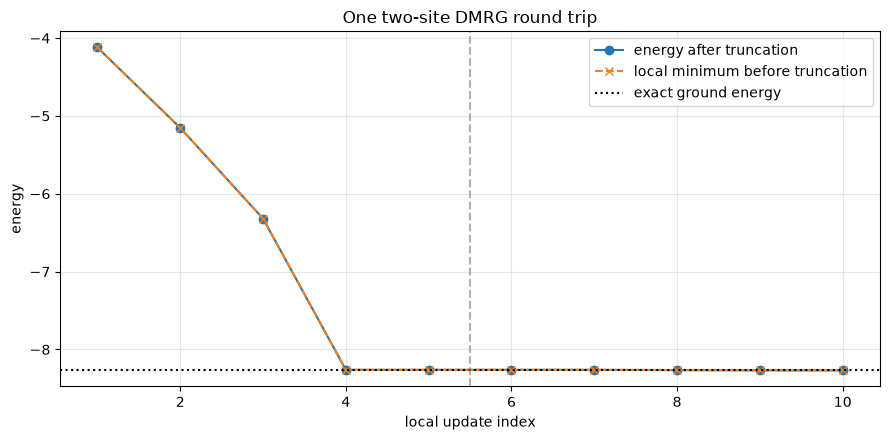

In [42]:
if LEFT_PASS_RESULT is not None and RIGHT_PASS_RESULT is not None:
    FINAL_MPS_CORES = LEFT_PASS_RESULT.cores
    SWEEP_LOGS = RIGHT_PASS_RESULT.logs + LEFT_PASS_RESULT.logs
    FINAL_STATE = tt_reconstruct(FINAL_MPS_CORES).reshape(-1)
    final_norm = torch.vdot(FINAL_STATE, FINAL_STATE).real
    final_energy_dense = normalized_energy(FINAL_STATE, H_DENSE)
    final_energy_mpo = mps_mpo_energy(FINAL_MPS_CORES, MPO_CORES)
    final_global_residual = global_residual(FINAL_STATE, H_DENSE)
    exact_ground_energy = torch.linalg.eigvalsh(H_DENSE)[0]
    energy_gap_to_exact = final_energy_dense - exact_ground_energy

    torch.testing.assert_close(
        final_norm,
        final_norm.new_tensor(1.0),
        atol=ATOL,
        rtol=RTOL,
    )
    torch.testing.assert_close(
        final_energy_dense,
        final_energy_mpo,
        atol=ATOL,
        rtol=RTOL,
    )
    assert all(log.local_residual <= ATOL for log in SWEEP_LOGS)

    print("one round-trip sweep: OK")
    print("final TT-ranks:", tt_ranks(FINAL_MPS_CORES))
    print("final norm:", final_norm.item())
    print("final energy:", final_energy_dense.item())
    print("exact ground energy:", exact_ground_energy.item())
    print("energy difference:", energy_gap_to_exact.item())
    print("global residual:", final_global_residual.item())
    print()
    print("direction  pair  rank  local_minimum       discarded_weight    energy_after        local_residual")
    for log in SWEEP_LOGS:
        pair_label = f"({log.pair_start}, {log.pair_start + 1})"
        print(
            f"{log.direction:>9}  {pair_label:>6}  {log.retained_rank:>4d}  "
            f"{log.local_minimum_energy:>18.10f}  "
            f"{log.discarded_weight:>18.3e}  "
            f"{log.energy_after:>18.10f}  "
            f"{log.local_residual:>14.3e}"
        )

    update_indices = list(range(1, len(SWEEP_LOGS) + 1))
    energies_after = [log.energy_after for log in SWEEP_LOGS]
    local_minima = [log.local_minimum_energy for log in SWEEP_LOGS]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(update_indices, energies_after, marker="o", label="energy after truncation")
    ax.plot(update_indices, local_minima, marker="x", linestyle="--", label="local minimum before truncation")
    ax.axhline(
        exact_ground_energy.item(),
        color="black",
        linestyle=":",
        label="exact ground energy",
    )
    ax.axvline(LENGTH - 1 + 0.5, color="gray", linestyle="--", alpha=0.6)
    ax.set_xlabel("local update index")
    ax.set_ylabel("energy")
    ax.set_title("One two-site DMRG round trip")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    FINAL_MPS_CORES = FINAL_STATE = None
    SWEEP_LOGS = None
    final_norm = final_energy_dense = final_energy_mpo = None
    final_global_residual = exact_ground_energy = energy_gap_to_exact = None
    print("one round-trip diagnostics: SKIP (the sweep TODOs are incomplete)")


## 10. 最後の整理問題

コードとログを見ながら、次を自分の言葉で説明してください。

1. 2個のcoreを縮約して$\Theta$を作るだけの場合と、$\Theta$を局所最適化する場合では、何が違うか。
2. 局所問題を解いている間に$L,R$が固定されるのは、どの量を最適化変数として選んだからか。
3. 右向きと左向きで、特異値を置く側を変える理由は何か。
4. 局所最小固有値と、切り捨て後の全体エネルギーが一致しないことがあるのはなぜか。
5. 逐次更新したenvironmentを、現在のMPSから再構築したenvironmentと比較する目的は何か。
6. 局所残差が小さくても、全体残差が小さいとは限らないのはなぜか。
7. 1往復を正しく実行できたことと、基底状態へ十分収束したことはどう違うか。

このNotebookで確認したのは、environmentベースの2-site局所更新を左右へ接続した**1往復**です。複数往復の収束判定やmatrix-free反復固有値solverは、次の段階で扱います。
